In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("D:\\SevenMentor\\ML\\workspace\\Dhanaji_ml\\dataset\\House Price Prediction Dataset.csv")

In [3]:
df

,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Location,Condition,Garage,Price
0,1,1360,5,4,3,1970,Downtown,Excellent,No,149919
1,2,4272,5,4,3,1958,Downtown,Excellent,No,424998
2,3,3592,2,2,3,1938,Downtown,Good,No,266746
3,4,966,4,2,2,1902,Suburban,Fair,Yes,244020
4,5,4926,1,4,2,1975,Downtown,Fair,Yes,636056
...,...,...,...,...,...,...,...,...,...,...
1995,1996,4994,5,4,3,1923,Suburban,Poor,No,295620
1996,1997,3046,5,2,1,2019,Suburban,Poor,Yes,580929
1997,1998,1062,5,1,2,1903,Rural,Poor,No,476925
1998,1999,4062,3,1,2,1936,Urban,Excellent,Yes,161119


# data quelity


In [4]:
df.describe()

,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Price
count,2000.000000,2000.000000,2000.000000,2000.00000,2000.000000,2000.000000,2000.000000
mean,1000.500000,2786.209500,3.003500,2.55250,1.993500,1961.446000,537676.855000
std,577.494589,1295.146799,1.424606,1.10899,0.809188,35.926695,276428.845719
min,1.000000,501.000000,1.000000,1.00000,1.000000,1900.000000,50005.000000
25%,500.750000,1653.000000,2.000000,2.00000,1.000000,1930.000000,300098.000000
50%,1000.500000,2833.000000,3.000000,3.00000,2.000000,1961.000000,539254.000000
75%,1500.250000,3887.500000,4.000000,4.00000,3.000000,1993.000000,780086.000000
max,2000.000000,4999.000000,5.000000,4.00000,3.000000,2023.000000,999656.000000


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 10 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   Id         2000 non-null   int64
 1   Area       2000 non-null   int64
 2   Bedrooms   2000 non-null   int64
 3   Bathrooms  2000 non-null   int64
 4   Floors     2000 non-null   int64
 5   YearBuilt  2000 non-null   int64
 6   Location   2000 non-null   str  
 7   Condition  2000 non-null   str  
 8   Garage     2000 non-null   str  
 9   Price      2000 non-null   int64
dtypes: int64(7), str(3)
memory usage: 156.4 KB


In [6]:
# find unique values in each column
for column in df.columns:
    unique_values = df[column].unique()
    print(f"Unique values in column '{column}': {unique_values}")

Unique values in column 'Id': [   1    2    3 ... 1998 1999 2000]
Unique values in column 'Area': [1360 4272 3592 ...  865 2174 4062]
Unique values in column 'Bedrooms': [5 2 4 1 3]
Unique values in column 'Bathrooms': [4 2 1 3]
Unique values in column 'Floors': [3 2 1]
Unique values in column 'YearBuilt': [1970 1958 1938 1902 1975 1906 1948 1925 1932 2000 1947 1978 1901 2004
 1931 1903 1919 2013 2016 1935 1927 1976 1900 1959 1955 1934 2011 1929
 1953 2020 1954 1988 1979 1957 1982 1964 1968 1950 1921 1987 2006 2008
 2015 1952 1999 1967 1951 1981 1949 1940 1917 1965 1920 1943 2002 1946
 1928 1989 1984 1916 1930 2014 1972 1994 1977 2009 1913 1996 1998 2010
 1983 2022 1915 1911 2018 1904 1980 2021 2005 1973 1942 1944 1908 1961
 1956 1924 1914 1905 2019 1941 1992 1974 1963 2001 1991 1936 1907 1997
 2007 2017 1966 1945 1912 1986 1960 1995 1933 1969 1923 2012 1910 2003
 1993 2023 1918 1971 1926 1939 1922 1937 1909 1990 1962 1985]
Unique values in column 'Location': <StringArray>
['Downtown',

# remove unwanted columns



In [7]:
df = df.drop("Id", axis=1)

# EDA

Text(0, 0.5, 'Price')

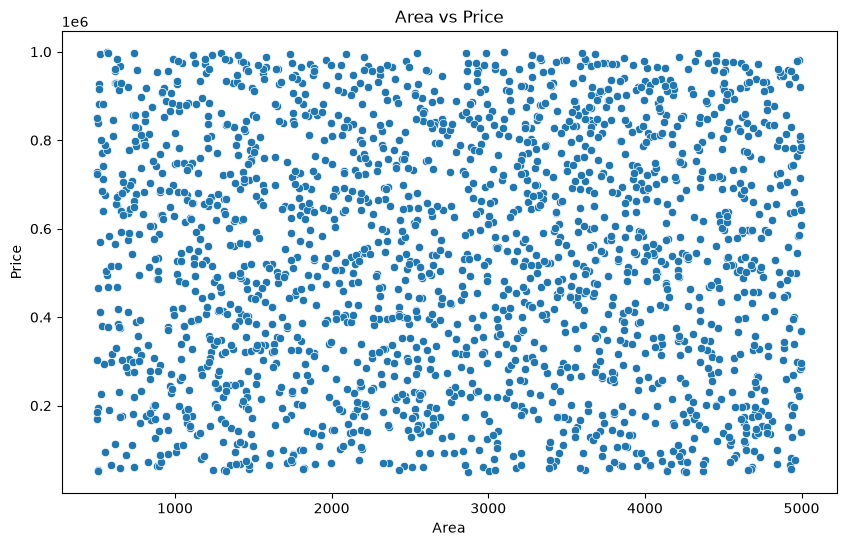

In [8]:
# Area vs Price


import seaborn as sb
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
sb.scatterplot(x='Area', y='Price', data=df)
plt.title('Area vs Price')
plt.xlabel('Area')  
plt.ylabel('Price')

<Axes: >

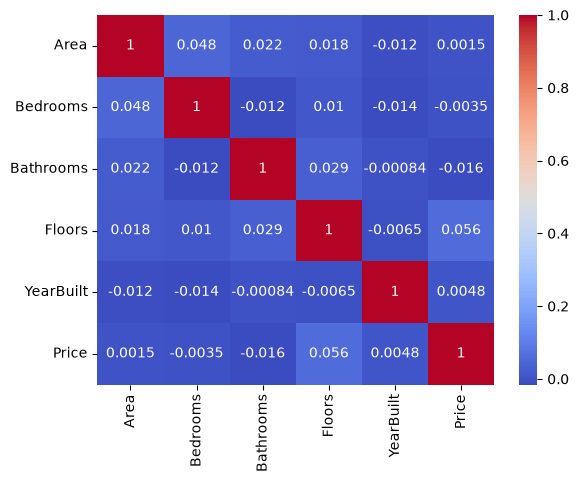

In [9]:
# correlation analysis
plt.Figure(figsize=(10,5))
sb.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap='coolwarm'
)

# plt.title("")

<Axes: xlabel='Location', ylabel='Price'>

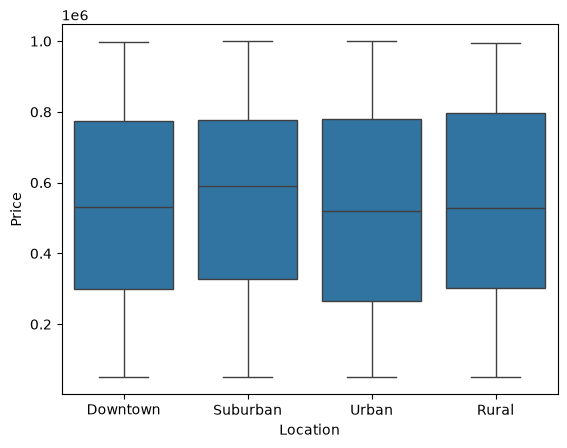

In [10]:
sb.boxplot(data = df,
            x = "Location",
            y="Price")

# Define Target

In [11]:
Y = df["Price"]
X = df.drop("Price", axis=1)

# Train the model

In [12]:
from sklearn.model_selection import train_test_split

xtrain, xtest, ytrain, ytest = train_test_split(X,Y, test_size=0.2, random_state=42)

In [13]:
print("train:", xtrain.shape, xtest.shape)
print("Test:", ytrain.shape, ytest.shape)

train: (1600, 8) (400, 8)
Test: (1600,) (400,)


In [14]:
numeric = []
categorical = []

for i in X.columns:
    if df[i].dtype == "str":
        categorical.append(i)
    else:
        numeric.append(i)

In [15]:
numeric

['Area', 'Bedrooms', 'Bathrooms', 'Floors', 'YearBuilt']

In [16]:
categorical

['Location', 'Condition', 'Garage']

In [17]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder


numerical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="mean")),
        ("scaler", StandardScaler())
    ])

categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

In [18]:
from sklearn.compose import ColumnTransformer
preprocessor = ColumnTransformer([
        ("num", numerical_pipeline, numeric),
        ("cat", categorical_pipeline, categorical)
    ])

In [19]:
X.isnull().sum()

Area         0
Bedrooms     0
Bathrooms    0
Floors       0
YearBuilt    0
Location     0
Condition    0
Garage       0
dtype: int64

In [20]:
xtrain_preprocessed = preprocessor.fit_transform(xtrain)
xtest_preprocessed = preprocessor.transform(xtest)

In [21]:
converted_df = pd.DataFrame(
    xtrain_preprocessed,
    columns=preprocessor.get_feature_names_out()
)

converted_df




,num__Area,num__Bedrooms,num__Bathrooms,num__Floors,num__YearBuilt,cat__Location_Downtown,cat__Location_Rural,cat__Location_Suburban,cat__Location_Urban,cat__Condition_Excellent,cat__Condition_Fair,cat__Condition_Good,cat__Condition_Poor,cat__Garage_No,cat__Garage_Yes
0,1.314081,0.685758,1.316088,1.242260,-0.808673,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0
1,-1.315960,-0.014889,0.414272,-1.236064,0.221883,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
2,-1.039194,-0.014889,1.316088,-1.236064,0.862499,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0
3,-0.088966,-0.715536,0.414272,-1.236064,0.277589,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
4,0.393836,-0.715536,1.316088,-1.236064,0.528264,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1595,0.545288,1.386405,0.414272,1.242260,-0.864379,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
1596,-0.789337,-0.014889,0.414272,0.003098,-0.585850,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
1597,-0.991529,-0.715536,0.414272,1.242260,0.305442,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
1598,0.524531,1.386405,1.316088,-1.236064,-0.195910,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0


In [22]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(xtrain_preprocessed, ytrain)

y_pred = model.predict(xtest_preprocessed)

In [23]:
y_pred

array([521988.22189839, 549119.31196651, 487101.22235594, 539752.7439933 ,
       553242.24872512, 521375.92025826, 523320.18080583, 578133.64353335,
       545899.64738458, 577368.69940644, 549359.90237922, 583802.8656311 ,
       511024.20843161, 527181.17287186, 502178.93122353, 563657.42139779,
       533851.47058016, 557566.45545641, 578893.4890812 , 522197.01288502,
       535945.37429884, 520333.81440515, 520145.76012635, 589984.6964629 ,
       570910.91251258, 530657.68307139, 524849.79926253, 533833.03412407,
       517535.08657939, 489462.64631857, 471135.44970754, 532885.36922583,
       559703.53345149, 566918.76753933, 505186.85760171, 504126.65238569,
       566525.93875815, 587039.42913431, 533334.54147469, 503067.97932305,
       488794.10065586, 540580.91705316, 538165.7543287 , 538208.1073811 ,
       539782.8193264 , 574195.17961934, 551957.63060142, 537147.22385255,
       531554.19942009, 528480.27403638, 515181.27688738, 549393.77262824,
       567112.62323004, 5

In [24]:
model.score(xtest_preprocessed, ytest)

-0.006717808430749761

# Model Evaluation

In [25]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [26]:
mean_squared_error(ytest, model.predict(xtest_preprocessed))

78321466146.0328